# Two-Stage Patient-Level Classification (AD vs REST, then CN vs MCI)

Stage 1 is the ResNet-18 + DenseNet-121 Hybrid trained as AD vs REST, the best AD detector from the One-vs-All experiments.
Stage 2 separates CN from MCI for patients that stage 1 does not call AD. Several stage-2 models are compared with
5-fold patient-level cross-validation on the training patients only, and the winner is evaluated once on the held-out test patients.

The patient discovery, test split, fold assignment, preprocessing and training recipe are copied from
`Team_09_ResNet18_DenseNet121_Hybrid_PatientLevel.ipynb`, so the test set is the same 47 patients (AD=8, CN=13, MCI=26).

Run with **Save Version > Save & Run All** so it keeps running in the background. Expected time with all flags on: about 3.5 to 4 hours on a P100.

In [1]:
import os, json, math, random, shutil, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as mpl_cm
import seaborn as sns
from collections import defaultdict
from tqdm import tqdm
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import (
    resnet18, ResNet18_Weights,
    densenet121, DenseNet121_Weights,
    resnet50, ResNet50_Weights,
    efficientnet_b0, EfficientNet_B0_Weights,
)

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    precision_recall_fscore_support, f1_score,
)

warnings.filterwarnings('ignore')
import torch._dynamo
torch._dynamo.config.suppress_errors = True

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Device: cuda


## Configuration

In [2]:
DATA_ROOT  = "/kaggle/input/datasets/malakkhaled202300369/adni-data/adni_nifti_preprocessed"
OUTPUT_DIR = "/kaggle/working/preprocessed_dualcnn"
CKPT_DIR   = "/kaggle/working/checkpoints_dualcnn"
os.makedirs(CKPT_DIR, exist_ok=True)

# Data and splitting (same as the Hybrid patient-level notebook)
IMAGE_SIZE      = 224
PREPROCESS_MODE = 'gray3'
N_FOLDS         = 5
TEST_RATIO      = 0.15
BATCH_SIZE      = 32
NUM_WORKERS     = 2
VALID_EXTS      = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}

# Hybrid training recipe (unchanged)
PHASE_A_EPOCHS  = 8
PHASE_B_EPOCHS  = 15
PATIENCE        = 5
WARMUP_EPOCHS   = 2
LR_MIN          = 1e-6
LR_HEAD_A       = 3e-3
LR_HEAD_B       = 1e-3
LR_BACKBONE_B   = 1e-4
WEIGHT_DECAY    = 5e-5
GRAD_CLIP_NORM  = 1.0
HEAD_HIDDEN     = 384
HEAD_USE_BN     = True
DROPOUT         = 0.30
LABEL_SMOOTHING = 0.05
USE_RANDAUGMENT = True
RANDAUG_N       = 2
RANDAUG_M       = 7
RANDOM_ERASING  = 0.20
TTA_HFLIP       = True
FREEZE_BACKBONES    = True
UNFREEZE_LAST_BLOCK = True

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# What to run
RUN_OVA_BASELINE = True   # trains CN vs REST and MCI vs REST so the One-vs-All result on this exact split is available (about 1.5 h)
RUN_DEEP_STAGE2  = True   # trains the Hybrid as CN vs MCI, needed for stage-2 Grad-CAM (about 40 min)
VERBOSE_EPOCHS   = False  # True prints every epoch
N_BOOT           = 2000   # bootstrap resamples for confidence intervals
PCA_DIM          = 256

CLASS_NAMES = sorted([
    d for d in os.listdir(DATA_ROOT)
    if os.path.isdir(os.path.join(DATA_ROOT, d)) and d in ('AD', 'CN', 'MCI')
])
AD_IDX, CN_IDX, MCI_IDX = CLASS_NAMES.index('AD'), CLASS_NAMES.index('CN'), CLASS_NAMES.index('MCI')
print(f'Classes: {CLASS_NAMES}')

Classes: ['AD', 'CN', 'MCI']


## Patient discovery and leakage check

In [3]:
patient_classes = defaultdict(set)
patient_slices  = defaultdict(list)

for cls in CLASS_NAMES:
    cls_dir = os.path.join(DATA_ROOT, cls)
    for patient_id in os.listdir(cls_dir):
        patient_dir = os.path.join(cls_dir, patient_id)
        if not os.path.isdir(patient_dir):
            continue
        slices = [
            os.path.join(patient_dir, f)
            for f in os.listdir(patient_dir)
            if os.path.splitext(f)[1].lower() in VALID_EXTS
        ]
        if slices:
            patient_classes[patient_id].add(cls)
            patient_slices[(patient_id, cls)].extend(slices)

leakage_patients = {pid: c for pid, c in patient_classes.items() if len(c) > 1}
clean_patients = {
    pid: list(classes)[0]
    for pid, classes in patient_classes.items()
    if pid not in leakage_patients
}
print(f'Patients: {len(patient_classes)} | in more than one class (excluded): {len(leakage_patients)} | kept: {len(clean_patients)}')

Patients: 320 | in more than one class (excluded): 0 | kept: 320


## Hold-out test split (identical code and seed to the Hybrid notebook)

In [4]:
class_patients = defaultdict(list)
for pid, cls in clean_patients.items():
    class_patients[cls].append(pid)
for cls in CLASS_NAMES:
    random.shuffle(class_patients[cls])

test_patients, trainval_patients = [], []
for cls in CLASS_NAMES:
    pids = class_patients[cls]
    n_test = max(1, int(len(pids) * TEST_RATIO))
    test_patients.extend(pids[:n_test])
    trainval_patients.extend(pids[n_test:])
    print(f'  {cls:<4}: total={len(pids):>3} | test={n_test} | trainval={len(pids) - n_test}')

assert not (set(test_patients) & set(trainval_patients)), 'Patient overlap between test and trainval'

def expand(pids):
    out = []
    for pid in pids:
        c = clean_patients[pid]
        l = CLASS_NAMES.index(c)
        for path in patient_slices[(pid, c)]:
            out.append((path, l, pid))
    return out

test_entries = expand(test_patients)
split_fp = hashlib.md5(','.join(sorted(test_patients)).encode()).hexdigest()[:10]
print(f'Test patients: {len(test_patients)} | test slices: {len(test_entries)} | split fingerprint: {split_fp}')

  AD  : total= 54 | test=8 | trainval=46
  CN  : total= 88 | test=13 | trainval=75
  MCI : total=178 | test=26 | trainval=152
Test patients: 47 | test slices: 1261 | split fingerprint: eaa3e75453


## Cross-validation folds (same assignment as the Hybrid notebook)

In [5]:
trainval_by_class = defaultdict(list)
for pid in trainval_patients:
    trainval_by_class[clean_patients[pid]].append(pid)
for cls in CLASS_NAMES:
    random.shuffle(trainval_by_class[cls])

class_folds = {cls: [trainval_by_class[cls][i::N_FOLDS] for i in range(N_FOLDS)] for cls in CLASS_NAMES}

def fold_pids(k):
    train_p, val_p = [], []
    for cls in CLASS_NAMES:
        for j, chunk in enumerate(class_folds[cls]):
            (val_p if j == k else train_p).extend(chunk)
    return train_p, val_p

for k in range(N_FOLDS):
    tr, va = fold_pids(k)
    assert not (set(tr) & set(va))
print('Folds ready:', [len(fold_pids(k)[1]) for k in range(N_FOLDS)], 'validation patients per fold')

Folds ready: [56, 55, 54, 54, 54] validation patients per fold


## Cache slices as uint8 tensors

In [6]:
if os.path.exists(OUTPUT_DIR):
    shutil.rmtree(OUTPUT_DIR)
os.makedirs(OUTPUT_DIR, exist_ok=True)

all_entries = []
for pid, cls in clean_patients.items():
    label = CLASS_NAMES.index(cls)
    for path in patient_slices[(pid, cls)]:
        all_entries.append((path, label, pid))

fname_counts = {}
for path, label, pid in tqdm(all_entries, desc='Caching'):
    out_dir = os.path.join(OUTPUT_DIR, CLASS_NAMES[label])
    os.makedirs(out_dir, exist_ok=True)
    base = os.path.splitext(os.path.basename(path))[0]
    key = f'{pid}_{base}'.replace('/', '_').replace('\\', '_')
    fname_counts[key] = fname_counts.get(key, 0) + 1
    suffix = f'_dup{fname_counts[key]}' if fname_counts[key] > 1 else ''
    out_path = os.path.join(out_dir, f'{key}{suffix}.pt')
    if not os.path.exists(out_path):
        img = Image.open(path).convert('L').resize((IMAGE_SIZE, IMAGE_SIZE), Image.LANCZOS)
        tensor = (transforms.ToTensor()(img) * 255).byte().repeat(3, 1, 1)
        torch.save(tensor, out_path)

pt_lookup = {}
for cls in CLASS_NAMES:
    cls_dir = os.path.join(OUTPUT_DIR, cls)
    for fname in os.listdir(cls_dir):
        if fname.endswith('.pt'):
            pt_lookup[fname[:-3]] = os.path.join(cls_dir, fname)
print(f'Cached slices: {len(pt_lookup)}')

Caching: 100%|██████████| 8512/8512 [05:06<00:00, 27.76it/s]

Cached slices: 8512


## Dataset and augmentation (unchanged from the Hybrid notebook)

In [7]:
normalize = transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
_rand_aug = transforms.RandAugment(num_ops=RANDAUG_N, magnitude=RANDAUG_M) if USE_RANDAUGMENT else None
_erasing  = transforms.RandomErasing(p=RANDOM_ERASING, scale=(0.02, 0.12)) if RANDOM_ERASING > 0 else None

def apply_train_augment(t_byte):
    t = t_byte.clone()
    t = transforms.RandomHorizontalFlip(p=0.5)(t)
    if _rand_aug is not None:
        t = _rand_aug(t)
    t = t.float() / 255.0
    t = transforms.ColorJitter(brightness=0.15, contrast=0.15)(t)
    t = normalize(t)
    if _erasing is not None:
        t = _erasing(t)
    return t

class SliceDataset(Dataset):
    def __init__(self, entries, augment=False):
        self.augment = augment
        self.samples = []
        for path, label, pid in entries:
            base = os.path.splitext(os.path.basename(path))[0]
            key = f'{pid}_{base}'.replace('/', '_').replace('\\', '_')
            if key in pt_lookup:
                self.samples.append((pt_lookup[key], label, pid))
            else:
                for dup in range(2, 50):
                    dk = f'{key}_dup{dup}'
                    if dk in pt_lookup:
                        self.samples.append((pt_lookup[dk], label, pid))
                        break

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        pt_path, label, pid = self.samples[idx]
        t = torch.load(pt_path, weights_only=True)
        if self.augment:
            return apply_train_augment(t), label, pid
        return normalize(t.float() / 255.0), label, pid

def make_loader(entries, augment, shuffle):
    return DataLoader(SliceDataset(entries, augment=augment), batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=True)

def binarize(entries, pos_classes):
    return [(p, 1 if CLASS_NAMES[l] in pos_classes else 0, pid) for p, l, pid in entries]

## Hybrid model and two-phase training (unchanged recipe, quieter output)

In [8]:
def _make_head(in_dim, hidden, num_classes, dropout, use_bn):
    layers = [nn.Dropout(dropout)]
    if hidden:
        layers += [nn.Linear(in_dim, hidden)]
        if use_bn:
            layers += [nn.BatchNorm1d(hidden)]
        layers += [nn.GELU(), nn.Dropout(max(0.0, dropout * 0.5)), nn.Linear(hidden, num_classes)]
    else:
        layers += [nn.Linear(in_dim, num_classes)]
    return nn.Sequential(*layers)

class ResNetDenseNetHybrid(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        r = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
        r.fc = nn.Identity()
        d = densenet121(weights=DenseNet121_Weights.IMAGENET1K_V1)
        d.classifier = nn.Identity()
        self.resnet = r
        self.densenet = d
        if FREEZE_BACKBONES:
            for p in self.resnet.parameters():
                p.requires_grad = False
            for p in self.densenet.parameters():
                p.requires_grad = False
        self.head = _make_head(512 + 1024, HEAD_HIDDEN, num_classes, DROPOUT, HEAD_USE_BN)

    def forward(self, x):
        return self.head(torch.cat([self.resnet(x), self.densenet(x)], dim=1))

def freeze_all_but_head(model):
    for p in model.parameters():
        p.requires_grad = False
    for p in model.head.parameters():
        p.requires_grad = True

def unfreeze_last_blocks(model):
    for p in model.resnet.layer4.parameters():
        p.requires_grad = True
    for p in model.densenet.features.denseblock4.parameters():
        p.requires_grad = True
    for p in model.densenet.features.norm5.parameters():
        p.requires_grad = True

def set_training_mode(model, training, phase_b=False):
    if not training:
        model.eval()
        return
    model.train()
    model.resnet.eval()
    model.densenet.eval()
    if phase_b:
        model.resnet.layer4.train(True)
        model.densenet.features.denseblock4.train(True)
        model.densenet.features.norm5.train(True)
    model.head.train(True)

def build_optimizer(model, lr_head, lr_backbone=None):
    head_ids = {id(p) for p in model.head.parameters()}
    groups = [{'params': list(model.head.parameters()), 'lr': lr_head}]
    back = [p for p in model.parameters() if p.requires_grad and id(p) not in head_ids]
    if back and lr_backbone:
        groups.append({'params': back, 'lr': lr_backbone})
    return optim.AdamW(groups, weight_decay=WEIGHT_DECAY)

def cosine_with_warmup(optimizer, total_epochs, warmup):
    for g in optimizer.param_groups:
        g['initial_lr'] = g['lr']
    def lr_lambda(epoch):
        if epoch < warmup:
            return (epoch + 1) / max(1, warmup)
        progress = (epoch - warmup) / max(1, total_epochs - warmup)
        return max(LR_MIN / optimizer.param_groups[0]['initial_lr'], 0.5 * (1.0 + math.cos(math.pi * progress)))
    return optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

def run_epoch(loader, model, criterion, optimizer=None, scaler=None, phase_b=False):
    is_train = optimizer is not None
    set_training_mode(model, is_train, phase_b=phase_b)
    dev_type = 'cuda' if device.type == 'cuda' else 'cpu'
    total_loss = correct = total = 0
    ctx = torch.enable_grad() if is_train else torch.no_grad()
    with ctx:
        for images, labels, _ in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            with torch.amp.autocast(device_type=dev_type, enabled=(device.type == 'cuda')):
                outputs = model(images)
                loss = criterion(outputs, labels)
            if is_train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                if GRAD_CLIP_NORM:
                    scaler.unscale_(optimizer)
                    nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], GRAD_CLIP_NORM)
                scaler.step(optimizer)
                scaler.update()
            correct += (outputs.argmax(1) == labels).sum().item()
            total_loss += loss.item() * labels.size(0)
            total += labels.size(0)
    return total_loss / max(total, 1), correct / max(total, 1)

def train_phase(model, optimizer, scheduler, n_epochs, ckpt_path, best_acc, phase_b, train_loader, val_loader, criterion):
    scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))
    patience_ctr = 0
    for epoch in range(1, n_epochs + 1):
        tl, ta = run_epoch(train_loader, model, criterion, optimizer, scaler, phase_b=phase_b)
        vl, va = run_epoch(val_loader, model, criterion, phase_b=phase_b)
        scheduler.step()
        if VERBOSE_EPOCHS:
            print(f'    ep {epoch:02d} train acc {ta*100:.1f}% | val acc {va*100:.1f}%')
        if va > best_acc + 1e-5:
            best_acc = va
            patience_ctr = 0
            torch.save(model.state_dict(), ckpt_path)
        else:
            patience_ctr += 1
            if patience_ctr >= PATIENCE:
                break
    return best_acc

def train_two_phase(model, ckpt_path, train_loader, val_loader, criterion):
    freeze_all_but_head(model)
    opt_a = build_optimizer(model, LR_HEAD_A)
    best = train_phase(model, opt_a, cosine_with_warmup(opt_a, PHASE_A_EPOCHS, WARMUP_EPOCHS),
                       PHASE_A_EPOCHS, ckpt_path, 0.0, False, train_loader, val_loader, criterion)
    if UNFREEZE_LAST_BLOCK:
        model.load_state_dict(torch.load(ckpt_path, map_location=device, weights_only=True))
        unfreeze_last_blocks(model)
        opt_b = build_optimizer(model, LR_HEAD_B, LR_BACKBONE_B)
        best = train_phase(model, opt_b, cosine_with_warmup(opt_b, PHASE_B_EPOCHS, WARMUP_EPOCHS),
                           PHASE_B_EPOCHS, ckpt_path, best, True, train_loader, val_loader, criterion)
    model.load_state_dict(torch.load(ckpt_path, map_location=device, weights_only=True))
    model.to(device).eval()
    return best

## Patient-level prediction and cross-validated training

`predict_patient_probs` averages the positive-class probability over all slices of each patient (weighted fold ensemble, horizontal-flip TTA as in the Hybrid notebook).
`train_cv` trains one model per fold and also returns out-of-fold probabilities for every validation patient, which are used for threshold tuning and model selection without touching the test set.

In [9]:
def predict_patient_probs(models, weights, entries, use_tta=True):
    loader = make_loader(entries, augment=False, shuffle=False)
    dev_type = 'cuda' if device.type == 'cuda' else 'cpu'
    sums, counts = defaultdict(float), defaultdict(int)
    for m in models:
        m.to(device).eval()
    with torch.no_grad():
        for images, _, pids in loader:
            images = images.to(device, non_blocking=True)
            p = np.zeros(images.size(0))
            for m, w in zip(models, weights):
                with torch.amp.autocast(device_type=dev_type, enabled=(device.type == 'cuda')):
                    logits = m(images)
                    if use_tta:
                        logits = logits + m(torch.flip(images, dims=[-1]))
                p += w * torch.softmax(logits.float(), dim=1)[:, 1].cpu().numpy()
            for pi, pid in zip(p, pids):
                sums[pid] += float(pi)
                counts[pid] += 1
    for m in models:
        m.to('cpu')
    torch.cuda.empty_cache()
    return {pid: sums[pid] / counts[pid] for pid in sums}

def train_cv(task, pos_classes, include_classes):
    models, val_accs, oof = [], [], {}
    for k in range(N_FOLDS):
        tr_p, va_p = fold_pids(k)
        tr_p = [p for p in tr_p if clean_patients[p] in include_classes]
        va_in = [p for p in va_p if clean_patients[p] in include_classes]
        tr = binarize(expand(tr_p), pos_classes)
        va = binarize(expand(va_in), pos_classes)
        pos = sum(1 for _, l, _ in tr if l == 1)
        neg = len(tr) - pos
        cw = torch.tensor([len(tr) / (2.0 * max(neg, 1)), len(tr) / (2.0 * max(pos, 1))], dtype=torch.float32, device=device)
        criterion = nn.CrossEntropyLoss(weight=cw, label_smoothing=LABEL_SMOOTHING)
        model = ResNetDenseNetHybrid(2).to(device)
        ckpt_path = os.path.join(CKPT_DIR, f'{task}_fold{k+1}.pt')
        train_two_phase(model, ckpt_path, make_loader(tr, True, True), make_loader(va, False, False), criterion)

        val_probs = predict_patient_probs([model], [1.0], va, use_tta=False)
        val_true = {pid: l for _, l, pid in va}
        acc = np.mean([(val_probs[p] >= 0.5) == val_true[p] for p in val_probs])
        val_accs.append(float(acc))
        oof.update(predict_patient_probs([model], [1.0], expand(va_p), use_tta=TTA_HFLIP))
        models.append(model.to('cpu'))
        print(f'  {task} fold {k+1}: train patients {len(tr_p)} | patient-level val acc {acc*100:.2f}%')
    weights = np.array(val_accs) / np.sum(val_accs)
    print(f'  {task} CV mean {np.mean(val_accs)*100:.2f}% +/- {np.std(val_accs)*100:.2f}%')
    return models, weights, oof

In [10]:
# Fix 1: training loaders drop the last incomplete batch, because a batch of one slice breaks BatchNorm in the head.
# Fix 2: reuse fold models that finished in the previous run (attach its output with Add Input > Your Work).
# Only tasks that finished completely are reused. CN_vs_MCI is always retrained.

def make_loader(entries, augment, shuffle):
    return DataLoader(SliceDataset(entries, augment=augment), batch_size=BATCH_SIZE, shuffle=shuffle,
                      drop_last=shuffle, num_workers=NUM_WORKERS, pin_memory=True)

REUSE_TASKS = ['AD_vs_REST', 'CN_vs_REST', 'MCI_vs_REST']
REUSE_DIR = None
for root, _, files in os.walk('/kaggle/input'):
    if 'AD_vs_REST_fold1.pt' in files:
        REUSE_DIR = root
        break
print('Reusing checkpoints from:', REUSE_DIR if REUSE_DIR else 'none found, everything will be trained')

_train_two_phase_original = train_two_phase

def train_two_phase(model, ckpt_path, train_loader, val_loader, criterion):
    name = os.path.basename(ckpt_path)
    task = name.rsplit('_fold', 1)[0]
    src = os.path.join(REUSE_DIR, name) if REUSE_DIR else None
    if src and task in REUSE_TASKS and os.path.exists(src):
        model.load_state_dict(torch.load(src, map_location=device, weights_only=True))
        model.to(device).eval()
        shutil.copy(src, ckpt_path)
        print(f'  loaded {name}')
        return None
    return _train_two_phase_original(model, ckpt_path, train_loader, val_loader, criterion)

Reusing checkpoints from: none found, everything will be trained


## Metrics, bootstrap confidence intervals and threshold tuning

In [11]:
def three_class_metrics(y, pred):
    y, pred = np.array(y), np.array(pred)
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=[0, 1, 2], zero_division=0)
    out = {'acc': accuracy_score(y, pred), 'macro_P': p.mean(), 'macro_R': r.mean(), 'macro_F1': f.mean()}
    for i, c in enumerate(CLASS_NAMES):
        out[f'P_{c}'], out[f'R_{c}'], out[f'F1_{c}'] = p[i], r[i], f[i]
    return out

def bootstrap_ci(y, pred, n_boot=N_BOOT):
    y, pred = np.array(y), np.array(pred)
    rng = np.random.default_rng(SEED)
    f1s, recs = [], []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        _, r, f, _ = precision_recall_fscore_support(y[idx], pred[idx], labels=[0, 1, 2], zero_division=0)
        f1s.append(f.mean())
        recs.append(r.mean())
    return np.percentile(f1s, [2.5, 97.5]), np.percentile(recs, [2.5, 97.5])

def best_threshold(y, p):
    # threshold on the positive-class probability that maximizes binary macro-F1; ties go to the value closest to 0.5
    y, p = np.array(y), np.array(p)
    best_t, best_s = 0.5, -1
    for t in np.round(np.arange(0.05, 0.951, 0.01), 2):
        s = f1_score(y, (p >= t).astype(int), average='macro', zero_division=0)
        if s > best_s + 1e-9 or (abs(s - best_s) <= 1e-9 and abs(t - 0.5) < abs(best_t - 0.5)):
            best_t, best_s = t, s
    return best_t, best_s

def binary_report(name, y, p, t):
    pred = (np.array(p) >= t).astype(int)
    pr, rc, f, _ = precision_recall_fscore_support(y, pred, labels=[0, 1], zero_division=0)
    print(f'{name} @ t={t:.2f}: acc {accuracy_score(y, pred)*100:.2f}% | positive P {pr[1]:.2f} R {rc[1]:.2f} F1 {f[1]:.2f} | macro-F1 {f.mean():.2f}')

results = {}

def record(name, y, pred, show=False):
    m = three_class_metrics(y, pred)
    f1_ci, rec_ci = bootstrap_ci(y, pred)
    m['macro_F1_CI'] = [round(float(f1_ci[0]), 3), round(float(f1_ci[1]), 3)]
    m['macro_R_CI'] = [round(float(rec_ci[0]), 3), round(float(rec_ci[1]), 3)]
    m['n'] = len(y)
    results[name] = m
    if show:
        print(f'\n=== {name} (n={len(y)}) ===')
        print(classification_report(y, pred, labels=[0, 1, 2], target_names=CLASS_NAMES, zero_division=0, digits=3))
        print(f'macro-F1 95% CI [{f1_ci[0]:.3f}, {f1_ci[1]:.3f}] | macro recall (balanced accuracy) 95% CI [{rec_ci[0]:.3f}, {rec_ci[1]:.3f}]')
    return m

## Stage 1: Hybrid AD vs REST

In [12]:
s1_models, s1_w, s1_oof = train_cv('AD_vs_REST', ['AD'], CLASS_NAMES)

test_true = {pid: CLASS_NAMES.index(clean_patients[pid]) for pid in test_patients}
test_pids = sorted(test_patients)
y_test = [test_true[p] for p in test_pids]

p_ad_test = predict_patient_probs(s1_models, s1_w, test_entries, use_tta=TTA_HFLIP)

oof_pids = sorted(s1_oof)
y_oof_ad = [1 if clean_patients[p] == 'AD' else 0 for p in oof_pids]
T1, t1_score = best_threshold(y_oof_ad, [s1_oof[p] for p in oof_pids])
print(f'\nStage-1 threshold tuned on out-of-fold training patients: {T1:.2f} (OOF macro-F1 {t1_score:.3f})')

y_test_ad = [1 if y == AD_IDX else 0 for y in y_test]
binary_report('Stage 1 test', y_test_ad, [p_ad_test[p] for p in test_pids], 0.5)
binary_report('Stage 1 test', y_test_ad, [p_ad_test[p] for p in test_pids], T1)
print('Earlier Hybrid run, same split: acc 82.98% | AD P 0.50 R 0.38 F1 0.43 | macro-F1 0.66')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 177MB/s]


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 162MB/s]


  AD_vs_REST fold 1: train patients 217 | patient-level val acc 82.14%
  AD_vs_REST fold 2: train patients 218 | patient-level val acc 80.00%
  AD_vs_REST fold 3: train patients 219 | patient-level val acc 85.19%
  AD_vs_REST fold 4: train patients 219 | patient-level val acc 87.04%
  AD_vs_REST fold 5: train patients 219 | patient-level val acc 83.33%
  AD_vs_REST CV mean 83.54% +/- 2.43%

Stage-1 threshold tuned on out-of-fold training patients: 0.45 (OOF macro-F1 0.660)
Stage 1 test @ t=0.50: acc 93.62% | positive P 1.00 R 0.62 F1 0.77 | macro-F1 0.87
Stage 1 test @ t=0.45: acc 91.49% | positive P 0.83 R 0.62 F1 0.71 | macro-F1 0.83
Earlier Hybrid run, same split: acc 82.98% | AD P 0.50 R 0.38 F1 0.43 | macro-F1 0.66


## Baseline: One-vs-All argmax on this split (optional)

In [13]:
p_cn_test, p_mci_ova_test = None, None
if RUN_OVA_BASELINE:
    cn_models, cn_w, _ = train_cv('CN_vs_REST', ['CN'], CLASS_NAMES)
    mci_models, mci_w, _ = train_cv('MCI_vs_REST', ['MCI'], CLASS_NAMES)
    p_cn_test = predict_patient_probs(cn_models, cn_w, test_entries, use_tta=TTA_HFLIP)
    p_mci_ova_test = predict_patient_probs(mci_models, mci_w, test_entries, use_tta=TTA_HFLIP)
    ova_pred = []
    for p in test_pids:
        scores = np.zeros(3)
        scores[AD_IDX], scores[CN_IDX], scores[MCI_IDX] = p_ad_test[p], p_cn_test[p], p_mci_ova_test[p]
        ova_pred.append(int(np.argmax(scores)))
    record('Hybrid One-vs-All argmax (this run)', y_test, ova_pred, show=True)
    print('Earlier Hybrid run, same split: acc 63.83% | macro P 0.63 R 0.58 F1 0.58')
    del cn_models, mci_models

  CN_vs_REST fold 1: train patients 217 | patient-level val acc 71.43%
  CN_vs_REST fold 2: train patients 218 | patient-level val acc 78.18%
  CN_vs_REST fold 3: train patients 219 | patient-level val acc 74.07%
  CN_vs_REST fold 4: train patients 219 | patient-level val acc 64.81%
  CN_vs_REST fold 5: train patients 219 | patient-level val acc 64.81%
  CN_vs_REST CV mean 70.66% +/- 5.24%
  MCI_vs_REST fold 1: train patients 217 | patient-level val acc 48.21%
  MCI_vs_REST fold 2: train patients 218 | patient-level val acc 52.73%
  MCI_vs_REST fold 3: train patients 219 | patient-level val acc 66.67%
  MCI_vs_REST fold 4: train patients 219 | patient-level val acc 57.41%
  MCI_vs_REST fold 5: train patients 219 | patient-level val acc 62.96%
  MCI_vs_REST CV mean 57.60% +/- 6.68%

=== Hybrid One-vs-All argmax (this run) (n=47) ===
              precision    recall  f1-score   support

          AD      0.800     0.500     0.615         8
          CN      0.571     0.308     0.400    

## Stage 2 candidate A: Hybrid fine-tuned as CN vs MCI

In [14]:
s2_deep = None
if RUN_DEEP_STAGE2:
    s2_deep_models, s2_deep_w, s2_deep_oof = train_cv('CN_vs_MCI', ['MCI'], ['CN', 'MCI'])
    p_mci_deep_test = predict_patient_probs(s2_deep_models, s2_deep_w, test_entries, use_tta=TTA_HFLIP)
    s2_deep = {'oof': s2_deep_oof, 'test': p_mci_deep_test}

  CN_vs_MCI fold 1: train patients 181 | patient-level val acc 63.04%
  CN_vs_MCI fold 2: train patients 181 | patient-level val acc 65.22%
  CN_vs_MCI fold 3: train patients 182 | patient-level val acc 68.89%
  CN_vs_MCI fold 4: train patients 182 | patient-level val acc 62.22%
  CN_vs_MCI fold 5: train patients 182 | patient-level val acc 73.33%
  CN_vs_MCI CV mean 66.54% +/- 4.11%


## Stage 2 candidates B: frozen ImageNet features with classical classifiers

Features are extracted once per backbone (no fine-tuning, no augmentation). Each classifier is trained on slices of the CN and MCI training patients,
and slice probabilities are averaged per patient, the same aggregation as the deep models.

In [15]:
def build_extractor(name):
    if name == 'resnet18+densenet121':
        r = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1); r.fc = nn.Identity()
        d = densenet121(weights=DenseNet121_Weights.IMAGENET1K_V1); d.classifier = nn.Identity()
        class Both(nn.Module):
            def __init__(self):
                super().__init__()
                self.r, self.d = r, d
            def forward(self, x):
                return torch.cat([self.r(x), self.d(x)], dim=1)
        return Both()
    if name == 'resnet50':
        m = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2); m.fc = nn.Identity(); return m
    if name == 'densenet121':
        m = densenet121(weights=DenseNet121_Weights.IMAGENET1K_V1); m.classifier = nn.Identity(); return m
    if name == 'efficientnet_b0':
        m = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1); m.classifier = nn.Identity(); return m

BACKBONES = ['resnet18+densenet121', 'resnet50', 'densenet121', 'efficientnet_b0']

feat_ds = SliceDataset(all_entries, augment=False)
slice_label = np.array([l for _, l, _ in feat_ds.samples])
slice_pid = np.array([pid for _, _, pid in feat_ds.samples])
pid_idx = defaultdict(list)
for i, pid in enumerate(slice_pid):
    pid_idx[pid].append(i)
pid_idx = {k: np.array(v) for k, v in pid_idx.items()}

feats = {}
for name in BACKBONES:
    ext = build_extractor(name).to(device).eval()
    loader = DataLoader(feat_ds, batch_size=64, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
    out = []
    with torch.no_grad():
        for images, _, _ in loader:
            out.append(ext(images.to(device)).float().cpu().numpy())
    feats[name] = np.concatenate(out)
    del ext
    torch.cuda.empty_cache()
    print(f'{name}: features {feats[name].shape}')

resnet18+densenet121: features (8512, 1536)
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 206MB/s]


resnet50: features (8512, 2048)
densenet121: features (8512, 1024)
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 142MB/s] 


efficientnet_b0: features (8512, 1280)


In [16]:
CLASSIFIERS = ['logreg', 'linear_svm', 'rbf_svm', 'random_forest', 'mlp']

def make_clf(name, n_samples):
    pca = PCA(n_components=min(PCA_DIM, n_samples - 1), random_state=SEED)
    if name == 'logreg':
        clf = LogisticRegression(C=0.1, class_weight='balanced', max_iter=3000)
    elif name == 'linear_svm':
        clf = CalibratedClassifierCV(LinearSVC(C=0.01, class_weight='balanced', max_iter=10000), cv=3)
    elif name == 'rbf_svm':
        clf = SVC(kernel='rbf', C=1.0, gamma='scale', probability=True, class_weight='balanced', random_state=SEED)
    elif name == 'random_forest':
        clf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced_subsample',
                                     n_jobs=-1, random_state=SEED)
    elif name == 'mlp':
        clf = MLPClassifier(hidden_layer_sizes=(256,), alpha=1e-3, early_stopping=True, max_iter=300, random_state=SEED)
    return make_pipeline(StandardScaler(), pca, clf)

def patient_mean(prob, pids):
    sums, counts = defaultdict(float), defaultdict(int)
    for pr, pid in zip(prob, pids):
        sums[pid] += pr
        counts[pid] += 1
    return {pid: sums[pid] / counts[pid] for pid in sums}

def idx_of(pids):
    return np.concatenate([pid_idx[p] for p in pids])

candidates = {}
for bb in BACKBONES:
    X = feats[bb]
    for cn in CLASSIFIERS:
        oof = {}
        for k in range(N_FOLDS):
            tr_p, va_p = fold_pids(k)
            tr_p = [p for p in tr_p if clean_patients[p] in ('CN', 'MCI')]
            tr_i, va_i = idx_of(tr_p), idx_of(va_p)
            clf = make_clf(cn, len(tr_i))
            clf.fit(X[tr_i], (slice_label[tr_i] == MCI_IDX).astype(int))
            oof.update(patient_mean(clf.predict_proba(X[va_i])[:, 1], slice_pid[va_i]))
        candidates[(bb, cn)] = {'oof': oof}
    print(f'{bb}: {len(CLASSIFIERS)} classifiers cross-validated')

if s2_deep is not None:
    candidates[('hybrid_finetuned', 'deep')] = {'oof': s2_deep['oof']}

resnet18+densenet121: 5 classifiers cross-validated
resnet50: 5 classifiers cross-validated
densenet121: 5 classifiers cross-validated
efficientnet_b0: 5 classifiers cross-validated


## Stage 2 model selection (training patients only)

Each candidate is scored on the out-of-fold CN and MCI training patients. The decision threshold is tuned on the same out-of-fold predictions.
The candidate with the highest macro-F1 is chosen. The test set is not used here.

In [17]:
nonad_oof = sorted(p for p in trainval_patients if clean_patients[p] in ('CN', 'MCI'))
y_nonad = [1 if clean_patients[p] == 'MCI' else 0 for p in nonad_oof]

rows = []
for key, c in candidates.items():
    probs = [c['oof'][p] for p in nonad_oof]
    f05 = f1_score(y_nonad, (np.array(probs) >= 0.5).astype(int), average='macro', zero_division=0)
    t, ft = best_threshold(y_nonad, probs)
    c['t2'] = t
    rows.append({'backbone': key[0], 'classifier': key[1], 'CV macro-F1 @0.5': round(f05, 3),
                 'tuned threshold': t, 'CV macro-F1 tuned': round(ft, 3)})

sel_table = pd.DataFrame(rows).sort_values('CV macro-F1 tuned', ascending=False).reset_index(drop=True)
print(sel_table.to_string())
sel_table.to_csv(os.path.join(CKPT_DIR, 'stage2_model_selection.csv'), index=False)

best_key = (sel_table.loc[0, 'backbone'], sel_table.loc[0, 'classifier'])
T2 = candidates[best_key]['t2']
print(f'\nSelected stage-2 model: {best_key} | threshold {T2:.2f}')

                backbone     classifier  CV macro-F1 @0.5  tuned threshold  CV macro-F1 tuned
0       hybrid_finetuned           deep             0.590             0.61              0.621
1        efficientnet_b0  random_forest             0.489             0.59              0.608
2        efficientnet_b0         logreg             0.581             0.60              0.595
3        efficientnet_b0        rbf_svm             0.548             0.70              0.592
4   resnet18+densenet121        rbf_svm             0.560             0.67              0.590
5        efficientnet_b0            mlp             0.553             0.71              0.578
6   resnet18+densenet121            mlp             0.575             0.48              0.578
7            densenet121         logreg             0.558             0.44              0.577
8            densenet121     linear_svm             0.401             0.66              0.573
9   resnet18+densenet121     linear_svm             0.401   

## Fit the selected stage-2 model on all CN and MCI training patients and predict the test patients

In [18]:
def stage2_test_probs(key):
    if key == ('hybrid_finetuned', 'deep'):
        return s2_deep['test']
    bb, cn = key
    X = feats[bb]
    tr_p = [p for p in trainval_patients if clean_patients[p] in ('CN', 'MCI')]
    tr_i, te_i = idx_of(tr_p), idx_of(test_patients)
    clf = make_clf(cn, len(tr_i))
    clf.fit(X[tr_i], (slice_label[tr_i] == MCI_IDX).astype(int))
    return patient_mean(clf.predict_proba(X[te_i])[:, 1], slice_pid[te_i])

p_mci_test = stage2_test_probs(best_key)

y_test_s2 = [1 if y == MCI_IDX else 0 for y, p in zip(y_test, test_pids) if y != AD_IDX]
pr_test_s2 = [p_mci_test[p] for y, p in zip(y_test, test_pids) if y != AD_IDX]
binary_report('Stage 2 alone, true CN/MCI test patients', y_test_s2, pr_test_s2, T2)

Stage 2 alone, true CN/MCI test patients @ t=0.61: acc 66.67% | positive P 0.72 R 0.81 F1 0.76 | macro-F1 0.60


## Final two-stage evaluation on the 47 test patients


=== Two-stage, thresholds 0.5 (n=47) ===
              precision    recall  f1-score   support

          AD      1.000     0.625     0.769         8
          CN      0.500     0.231     0.316        13
         MCI      0.639     0.885     0.742        26

    accuracy                          0.660        47
   macro avg      0.713     0.580     0.609        47
weighted avg      0.662     0.660     0.629        47

macro-F1 95% CI [0.430, 0.744] | macro recall (balanced accuracy) 95% CI [0.424, 0.727]

=== Two-stage, tuned thresholds (n=47) ===
              precision    recall  f1-score   support

          AD      0.833     0.625     0.714         8
          CN      0.455     0.385     0.417        13
         MCI      0.667     0.769     0.714        26

    accuracy                          0.638        47
   macro avg      0.652     0.593     0.615        47
weighted avg      0.636     0.638     0.632        47

macro-F1 95% CI [0.438, 0.756] | macro recall (balanced accuracy

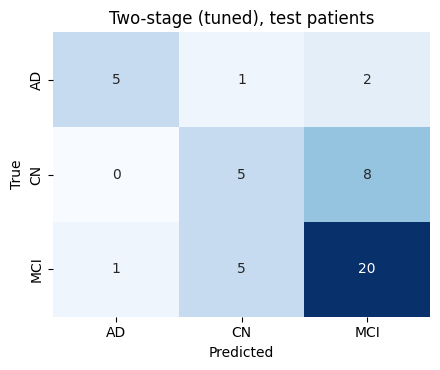

In [19]:
def two_stage_pred(p_ad, p_mci, pids, t1, t2):
    out = []
    for p in pids:
        if p_ad[p] >= t1:
            out.append(AD_IDX)
        elif p_mci[p] >= t2:
            out.append(MCI_IDX)
        else:
            out.append(CN_IDX)
    return out

pred_default = two_stage_pred(p_ad_test, p_mci_test, test_pids, 0.5, 0.5)
pred_tuned = two_stage_pred(p_ad_test, p_mci_test, test_pids, T1, T2)
record('Two-stage, thresholds 0.5', y_test, pred_default, show=True)
record('Two-stage, tuned thresholds', y_test, pred_tuned, show=True)

if s2_deep is not None and best_key != ('hybrid_finetuned', 'deep'):
    t2d = candidates[('hybrid_finetuned', 'deep')]['t2']
    record('Two-stage, fine-tuned Hybrid stage 2, tuned thresholds', y_test,
           two_stage_pred(p_ad_test, s2_deep['test'], test_pids, T1, t2d))

cm = confusion_matrix(y_test, pred_tuned, labels=[0, 1, 2])
plt.figure(figsize=(4.5, 3.8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Two-stage (tuned), test patients')
plt.tight_layout()
plt.savefig(os.path.join(CKPT_DIR, 'cm_two_stage.png'), dpi=200)
plt.show()

pd.DataFrame({'patient': test_pids, 'true': [CLASS_NAMES[y] for y in y_test],
              'p_AD': [p_ad_test[p] for p in test_pids], 'p_MCI_stage2': [p_mci_test[p] for p in test_pids],
              'pred': [CLASS_NAMES[y] for y in pred_tuned]}).to_csv(os.path.join(CKPT_DIR, 'test_predictions_two_stage.csv'), index=False)

## Single-stage 3-class baselines on frozen features (same split, for comparison)

In [20]:
tr_i, te_i = idx_of(trainval_patients), idx_of(test_patients)
for bb in BACKBONES:
    clf = make_pipeline(StandardScaler(), PCA(n_components=min(PCA_DIM, len(tr_i) - 1), random_state=SEED),
                        LogisticRegression(C=0.1, class_weight='balanced', max_iter=3000))
    clf.fit(feats[bb][tr_i], slice_label[tr_i])
    prob = clf.predict_proba(feats[bb][te_i])
    sums = defaultdict(lambda: np.zeros(3))
    for pr, pid in zip(prob, slice_pid[te_i]):
        sums[pid] += pr
    record(f'Single-stage 3-class, {bb} features + logistic regression', y_test, [int(np.argmax(sums[p])) for p in test_pids])
print('Baselines done.')

Baselines done.


## Cross-validated 3-class estimate on the 273 training patients

Stage 1 and stage 2 out-of-fold predictions are combined at threshold 0.5, so every training patient is predicted by models that never saw it.
This gives a larger-sample estimate to report next to the 47-patient test result.

In [21]:
oof_all = sorted(trainval_patients)
y_oof = [CLASS_NAMES.index(clean_patients[p]) for p in oof_all]
record('Two-stage, out-of-fold on training patients (thresholds 0.5)', y_oof,
       two_stage_pred(s1_oof, candidates[best_key]['oof'], oof_all, 0.5, 0.5), show=True)


=== Two-stage, out-of-fold on training patients (thresholds 0.5) (n=273) ===
              precision    recall  f1-score   support

          AD      0.524     0.239     0.328        46
          CN      0.455     0.333     0.385        75
         MCI      0.609     0.789     0.688       152

    accuracy                          0.571       273
   macro avg      0.529     0.454     0.467       273
weighted avg      0.552     0.571     0.544       273

macro-F1 95% CI [0.398, 0.533] | macro recall (balanced accuracy) 95% CI [0.396, 0.513]


{'acc': 0.5714285714285714,
 'macro_P': np.float64(0.5291640113975139),
 'macro_R': np.float64(0.4539791507754895),
 'macro_F1': np.float64(0.46688422555505477),
 'P_AD': np.float64(0.5238095238095238),
 'R_AD': np.float64(0.2391304347826087),
 'F1_AD': np.float64(0.3283582089552239),
 'P_CN': np.float64(0.45454545454545453),
 'R_CN': np.float64(0.3333333333333333),
 'F1_CN': np.float64(0.38461538461538464),
 'P_MCI': np.float64(0.6091370558375635),
 'R_MCI': np.float64(0.7894736842105263),
 'F1_MCI': np.float64(0.6876790830945558),
 'macro_F1_CI': [0.398, 0.533],
 'macro_R_CI': [0.396, 0.513],
 'n': 273}

## Results summary

In [22]:
summary = pd.DataFrame(results).T[['n', 'acc', 'macro_P', 'macro_R', 'macro_F1', 'macro_F1_CI', 'F1_AD', 'F1_CN', 'F1_MCI', 'R_AD', 'R_CN', 'R_MCI']]
pd.set_option('display.width', 250)
print(summary.round(3).to_string())
print('\nmacro_R is the macro recall, which equals balanced accuracy.')
print('Earlier Hybrid One-vs-All run on the same split: acc 0.638 | macro P 0.63 | macro R 0.58 | macro F1 0.58')

summary.to_csv(os.path.join(CKPT_DIR, 'results_summary.csv'))
with open(os.path.join(CKPT_DIR, 'results_summary.json'), 'w') as f:
    json.dump({'split_fingerprint': split_fp, 'stage1_threshold': T1, 'stage2_model': list(best_key),
               'stage2_threshold': T2, 'results': {k: {kk: (vv if isinstance(vv, list) else float(vv)) for kk, vv in v.items()} for k, v in results.items()}},
              f, indent=2)

                                                                             n       acc   macro_P   macro_R  macro_F1     macro_F1_CI     F1_AD     F1_CN    F1_MCI     R_AD      R_CN     R_MCI
Hybrid One-vs-All argmax (this run)                                         47  0.638298  0.666667  0.551282  0.578899   [0.393, 0.73]  0.615385       0.4  0.721311      0.5  0.307692  0.846154
Two-stage, thresholds 0.5                                                   47  0.659574  0.712963  0.580128  0.608985   [0.43, 0.744]  0.769231  0.315789  0.741935    0.625  0.230769  0.884615
Two-stage, tuned thresholds                                                 47  0.638298  0.651515  0.592949  0.615079  [0.438, 0.756]  0.714286  0.416667  0.714286    0.625  0.384615  0.769231
Single-stage 3-class, resnet18+densenet121 features + logistic regression   47  0.553191  0.533626  0.580128  0.543167  [0.379, 0.679]       0.5  0.551724  0.577778    0.625  0.615385       0.5
Single-stage 3-class, resnet50

## Grad-CAM

Grad-CAM on the ResNet-18 branch (last block of `layer4`), averaged over the fold ensemble with the same weights used for prediction.
Rows: an AD test patient explained by the stage-1 model, then a CN and an MCI test patient explained by the fine-tuned Hybrid stage-2 model.
Only patients the final two-stage pipeline classified correctly are shown, using each patient's middle slice.

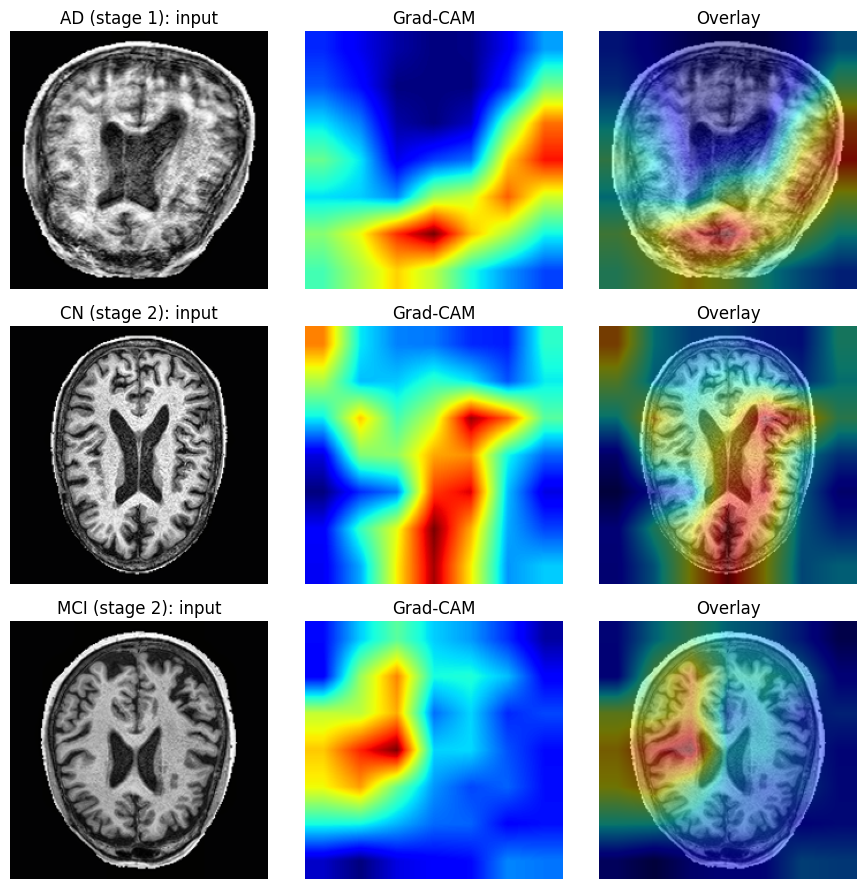

In [23]:
def gradcam_ensemble(models, weights, img, target):
    cam_sum = np.zeros((IMAGE_SIZE, IMAGE_SIZE))
    for m, w in zip(models, weights):
        m.to(device).eval()
        store = {}
        hook = m.resnet.layer4[-1].register_forward_hook(lambda mod, inp, out: store.update(act=out))
        x = img.unsqueeze(0).to(device).requires_grad_(True)
        with torch.enable_grad():
            logits = m(x)
            grad = torch.autograd.grad(logits[0, target], store['act'])[0]
        hook.remove()
        act = store['act'].detach()
        cam = F.relu((grad.mean(dim=(2, 3), keepdim=True) * act).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=(IMAGE_SIZE, IMAGE_SIZE), mode='bilinear', align_corners=False)
        cam = cam.squeeze().cpu().numpy()
        cam_sum += w * (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        m.to('cpu')
    torch.cuda.empty_cache()
    return (cam_sum - cam_sum.min()) / (cam_sum.max() - cam_sum.min() + 1e-8)

def middle_slice(pid):
    ds = SliceDataset(expand([pid]), augment=False)
    ds.samples.sort(key=lambda s: s[0])
    return ds[len(ds) // 2][0]

def denorm(t):
    x = t.permute(1, 2, 0).numpy() * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
    return np.clip(x, 0, 1)

panels = []
correct = {c: [p for p, y, pr in zip(test_pids, y_test, pred_tuned) if y == pr and y == CLASS_NAMES.index(c)] for c in CLASS_NAMES}
if correct['AD']:
    panels.append(('AD (stage 1)', correct['AD'][0], s1_models, s1_w, 1))
if s2_deep is not None:
    if correct['CN']:
        panels.append(('CN (stage 2)', correct['CN'][0], s2_deep_models, s2_deep_w, 0))
    if correct['MCI']:
        panels.append(('MCI (stage 2)', correct['MCI'][0], s2_deep_models, s2_deep_w, 1))

if panels:
    fig, axes = plt.subplots(len(panels), 3, figsize=(9, 3 * len(panels)))
    axes = np.atleast_2d(axes)
    for row, (title, pid, models, weights, target) in enumerate(panels):
        img = middle_slice(pid)
        cam = gradcam_ensemble(models, weights, img, target)
        raw = denorm(img)
        axes[row, 0].imshow(raw); axes[row, 0].set_title(f'{title}: input')
        axes[row, 1].imshow(cam, cmap='jet'); axes[row, 1].set_title('Grad-CAM')
        axes[row, 2].imshow(0.55 * raw + 0.45 * mpl_cm.jet(cam)[..., :3]); axes[row, 2].set_title('Overlay')
        for a in axes[row]:
            a.axis('off')
    plt.tight_layout()
    plt.savefig(os.path.join(CKPT_DIR, 'gradcam_two_stage.png'), dpi=200)
    plt.show()
    if best_key != ('hybrid_finetuned', 'deep'):
        print('Note: the selected stage-2 model is not the fine-tuned Hybrid, so the CN and MCI rows explain the fine-tuned Hybrid stage-2 candidate.')
else:
    print('No correctly classified patients available for Grad-CAM.')

## Save the trained models for later reuse

In [24]:
save_dir = os.path.join(CKPT_DIR, 'final_models')
os.makedirs(save_dir, exist_ok=True)
for k, m in enumerate(s1_models):
    torch.save(m.state_dict(), os.path.join(save_dir, f'stage1_AD_vs_REST_fold{k+1}.pt'))
if s2_deep is not None:
    for k, m in enumerate(s2_deep_models):
        torch.save(m.state_dict(), os.path.join(save_dir, f'stage2_CN_vs_MCI_fold{k+1}.pt'))
with open(os.path.join(save_dir, 'weights.json'), 'w') as f:
    json.dump({'stage1': s1_w.tolist(), 'stage2_deep': s2_deep_w.tolist() if s2_deep is not None else None,
               'T1': T1, 'T2': T2, 'stage2_selected': list(best_key)}, f, indent=2)
print('Saved to', save_dir)

Saved to /kaggle/working/checkpoints_dualcnn/final_models
